In [29]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as sp

In [2]:
num_cc = []
xx = []
for i in range(1000):
    df = pd.read_json(
        f"../data/processed/2021/bs_400_random/random_{i:03}/metrics_growth.json"
    )
    num_cc.append(df["num_cc"].values)
    xx.append(df["xx"].values)

In [3]:
num_cc = np.mean(np.transpose(num_cc), axis=1)
xx = np.mean(np.transpose(xx), axis=1)

In [4]:
num_cc_real = []
xx_real = []
for i in range(1000):
    df = pd.read_json(
        f"../data/processed/2021/bs_400_real_random/real_random_{i:03}/metrics_growth.json"
    )
    num_cc_real.append(df["num_cc"].values)
    xx_real.append(df["xx"].values)

In [5]:
num_cc_real = np.mean(np.transpose(num_cc_real), axis=1)
xx_real = np.mean(np.transpose(xx_real), axis=1)

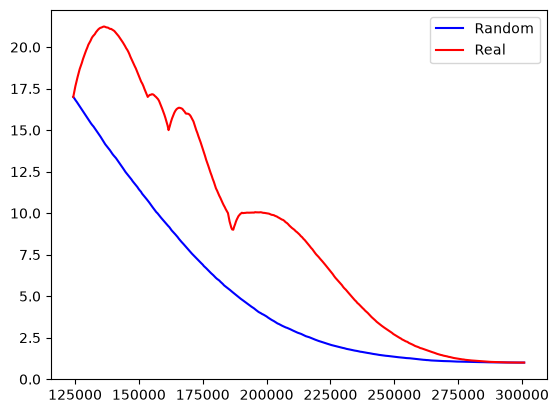

In [6]:
fig, ax = plt.subplots()
ax.plot(xx, num_cc, color="blue", label="Random")
ax.plot(xx_real, num_cc_real, color="red", label="Real")
ax.legend()

In [7]:
auc = pd.read_json("../data/processed/2021/auc_table_growth_bs_400.json")

In [8]:
mean_rand_cov = auc[auc["Metric optimized"] == "random"]["AUC of Coverage"].mean()

In [9]:
std_rand_cov = auc[auc["Metric optimized"] == "random"]["AUC of Coverage"].std()

In [10]:
mean_rand_dir = auc[auc["Metric optimized"] == "random"]["AUC of Directness"].mean()

In [11]:
std_rand_dir = auc[auc["Metric optimized"] == "random"]["AUC of Directness"].std()

In [12]:
real_cov = auc[auc["Metric optimized"] == "real_random"]["AUC of Coverage"].values[0]

In [13]:
real_dir = auc[auc["Metric optimized"] == "real_random"]["AUC of Directness"].values[0]

In [14]:
np.abs((real_cov - mean_rand_cov) / std_rand_cov)

np.float64(2.2821753611928726)

In [15]:
np.abs((real_dir - mean_rand_dir) / std_rand_dir)

np.float64(0.8406594267221013)

(array([  4.,   2.,   7.,  11.,  25.,  33.,  58.,  85.,  96., 108., 120.,
        113.,  97.,  92.,  54.,  42.,  29.,  11.,   9.,   4.]),
 array([0.60310292, 0.61052291, 0.6179429 , 0.62536289, 0.63278288,
        0.64020287, 0.64762286, 0.65504285, 0.66246284, 0.66988283,
        0.67730282, 0.68472281, 0.69214281, 0.6995628 , 0.70698279,
        0.71440278, 0.72182277, 0.72924276, 0.73666275, 0.74408274,
        0.75150273]),
 <BarContainer object of 20 artists>)

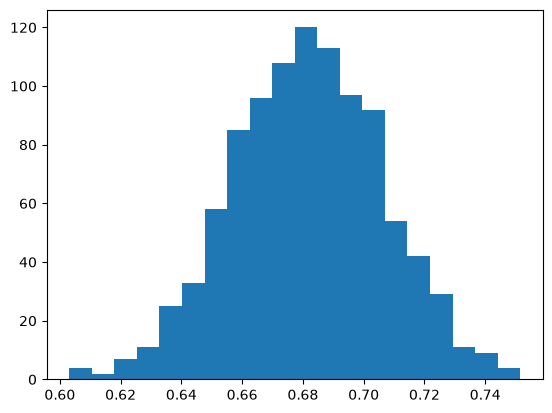

In [16]:
plt.hist(auc[auc["Metric optimized"] == "random"]["AUC of Coverage"].values, bins=20)

(array([  3.,   6.,   3.,  12.,  28.,  40.,  72.,  93., 125., 135., 127.,
        114.,  93.,  63.,  46.,  19.,  14.,   2.,   4.,   1.]),
 array([0.5850157 , 0.59023686, 0.59545801, 0.60067917, 0.60590033,
        0.61112149, 0.61634264, 0.6215638 , 0.62678496, 0.63200612,
        0.63722728, 0.64244843, 0.64766959, 0.65289075, 0.65811191,
        0.66333306, 0.66855422, 0.67377538, 0.67899654, 0.68421769,
        0.68943885]),
 <BarContainer object of 20 artists>)

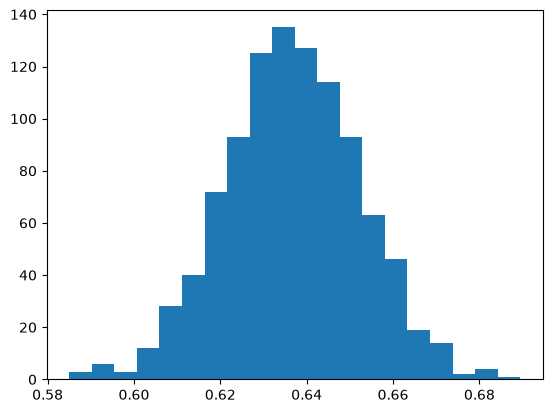

In [17]:
plt.hist(auc[auc["Metric optimized"] == "random"]["AUC of Directness"].values, bins=20)

In [19]:
sp.normaltest(auc[auc["Metric optimized"] == "random"]["AUC of Coverage"].values)

NormaltestResult(statistic=np.float64(0.6212039059846013), pvalue=np.float64(0.7330055884889382))

In [20]:
sp.normaltest(auc[auc["Metric optimized"] == "random"]["AUC of Directness"].values)

NormaltestResult(statistic=np.float64(0.9746925179409832), pvalue=np.float64(0.6142543050539977))

In [21]:
sp.kstest(
    (
        auc[auc["Metric optimized"] == "random"]["AUC of Directness"].values
        - mean_rand_dir
    )
    / std_rand_dir,
    "norm",
)

KstestResult(statistic=np.float64(0.012249734584471095), pvalue=np.float64(0.9978773279725471), statistic_location=np.float64(1.3061530044639456), statistic_sign=np.int8(-1))

In [22]:
sp.kstest(
    (auc[auc["Metric optimized"] == "random"]["AUC of Coverage"].values - mean_rand_cov)
    / std_rand_cov,
    "norm",
)

KstestResult(statistic=np.float64(0.015593979022518356), pvalue=np.float64(0.9650449554618621), statistic_location=np.float64(0.6575737885163806), statistic_sign=np.int8(-1))

In [26]:
sp.shapiro(auc[auc["Metric optimized"] == "random"]["AUC of Directness"].values)

ShapiroResult(statistic=np.float64(0.9990553389904646), pvalue=np.float64(0.9001601111351015))

In [27]:
sp.shapiro(auc[auc["Metric optimized"] == "random"]["AUC of Coverage"].values)

ShapiroResult(statistic=np.float64(0.9989158351368144), pvalue=np.float64(0.826741017113487))

In [23]:
sp.ttest_ind(
    real_cov, auc[auc["Metric optimized"] == "random"]["AUC of Coverage"].values
)

TtestResult(statistic=np.float64(2.28103512861548), pvalue=np.float64(0.022756169139903325), df=np.float64(999.0))

In [24]:
sp.ttest_ind(
    real_dir, auc[auc["Metric optimized"] == "random"]["AUC of Directness"].values
)

TtestResult(statistic=np.float64(-0.8402394119935488), pvalue=np.float64(0.4009752107433401), df=np.float64(999.0))

In [28]:
sp.ttest_ind(
    [real_cov, real_dir],
    auc[auc["Metric optimized"] == "random"][
        ["AUC of Coverage", "AUC of Directness"]
    ].values,
)

TtestResult(statistic=array([ 2.28103513, -0.84023941]), pvalue=array([0.02275617, 0.40097521]), df=array([999., 999.]))